# `ratio_study` - 03 Reporting

Automated PDF, XLSX, CSV and PNG output.

| Notebook | Covers |
|---|---|
| [01 Basics](01_basics.ipynb) | Sections 1-2: indicators, confidence intervals, compliance checks, IQR trimming, charts, comparisons |
| [02 Spatial](02_spatial.ipynb) | Section 3: ratio maps, Moran's I, hot/cold spots, the VEM map |
| [03 Reporting](03_reporting.ipynb) | Section 4: PDF / XLSX / CSV / PNG output |
| [04 Advanced diagnostics](04_advanced_diagnostics.ipynb) | Sections 5 and 7: ML / SHAP inequity diagnostics and sales-chasing detection |
| [05 Vertical equity](05_vertical_equity.ipynb) | Section 6: VEI, the Vertical Equity Panel, VEM, the Gini family |

All five use the anonymised sample dataset bundled with the package - no data preparation required.
Section numbers are kept from the original single-notebook tour so cross-references still line up.

## Setup

PDF output needs only the core install. Section 4.2 shows chart families; the ML page of the report needs the `ml` extra (see notebook 04).

In [1]:
# Uncomment on first run.
# %pip install "ratio_study[ml]"

In [2]:
import ratio_study as rs
import pandas as pd
import numpy as np
from pathlib import Path

# inline plotting must be enabled AFTER importing ratio_study
%matplotlib inline

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)

sample_df = rs.load_sample_dataset()

MARKET_VALUE = 'time_adjusted_sale_price'   # the market value proxy
ASSESSMENT   = 'assessment_value_new'       # the value under test (current CAMA model)

sample_df['asr'] = sample_df[ASSESSMENT] / sample_df[MARKET_VALUE]   # ratio column, needed by the spatial and VE functions

results_directory = Path().resolve()   # outputs are written here
print('results will be written to:', results_directory)

print('ratio_study version:', rs.__version__)
print(f'{len(sample_df):,} sales, {sample_df.shape[1]} columns')

results will be written to: <path>ratio_study version: 0.4.5
12,583 sales, 20 columns


---
# 4. Automated reporting

The Standard sets out what a published ratio study owes its reader. The report should state
the purpose, identify data sources, and describe the methodology — sales time frame, data
edits, time trends, outlier trimming, statistics used, and the proper use of results — and
the exhibits should carry, for each stratum: the tax year, parcel and sale
counts, the number trimmed, level, uniformity, price-related bias, and confidence
intervals.

`ratios_report()` is `ratios()` plus publication: same arguments, same indicators, same
compliance commentary — and a finished PDF.

| Format | Argument | Contents |
|---|---|---|
| **PDF** | on by default | Ratio tables, compliance comments, charts, vertical equity panel |
| **XLSX** | `export_ratios='xlsx'` | One tab per grouping level |
| **CSV** | `export_ratios='csv'` | Flat table |
| **Both** | `export_ratios='both'` | XLSX and CSV |
| **ZIP / GZIP** | `export_in_compacted_file='zip'` | Everything above in one archive |
| **PNG** | `graph_filepath=` on any chart | Individual charts, for slides |

## 4.1 A report in one line

The function returns the ratios frame by default and writes the PDF to
`export_directory`.

One default to know about: `export_in_compacted_file='zip'`, so outputs are normally
bundled into an archive. Set it to `''` while exploring, to get the PDF on its own.

In [3]:
report = rs.ratios_report(sample_df,
                          assessment_header=ASSESSMENT,
                          market_value_header=MARKET_VALUE,
                          group_by='property_type',
                          descriptive=True,
                          model_name='DemoModel',
                          export_directory=results_directory,
                          export_in_compacted_file='',
                          return_dict=False)
report

Confidence interval settings  (<-- marks a value you set or is a default setting)
  Mode                  : distribution
  Level                 : 90%
  Indicators            : Median, Mean, Weighted_Mean, CoD, PRB, PRD
  Overall intervals     : on
  Per-group intervals   : off
  Minimum sales per row : 20
  Estimators            : Appendix D closed forms, plus PRB (regression) and PRD (delta method); bootstrap options ignored
VEI quantile method: R7


,Level,Group,Count,Median,Median_ci,Mean,Mean_ci,Weighted_Mean,Weighted_Mean_ci,CoD,CoD_ci,PRB,PRB_ci,PRD,PRD_ci,VEI,VEI_conclusion,VEI_kw_statistic,VEI_kw_pvalue,Inequity_conclusion,Inequity_severity,Inequity_prevalence,Comments Ratio Study Standard metrics,Median_acceptable,PRB_acceptable,PRD_acceptable,CoD_acceptable
0,Overall,,"12,583",0.9985,"(0.9968, 1.0001)",1.0089,"(1.0070, 1.0108)",0.9969,"(0.9946, 0.9993)",9.48%,"(9.36%, 9.61%)",-0.0178,"(-0.0216, -0.0139)",1.0120,"(1.0107, 1.0134)",-0.75,Acceptable,103.19,0.00,acceptable,0.00,0.00,,True,True,True,True
1,property_type,Bed and breakfast,3ø,1.1092,,1.1182,,1.1049,,,,,,,,0.00,Sample size too small,,,,,,Sample too small (3): some ratio indicators co...,False,,,
2,property_type,Duplex,354,1.0122,,1.0222,,1.0022,,11.06%,,-0.0736⊥,,1.0199,,-9.29,Acceptable,21.21,0.00,Regressivity,25.79,1.41,PRB suggests a review regarding assessment sta...,True,False,True,True
3,property_type,Fiveplex,30,0.9712,,0.9921,,0.9781,,9.54%,,-0.0590⊥,,1.0144,,0.17,Acceptable,0.27,0.60,Regressivity,19.67,6.67,PRB not significant at 95%,True,False,True,True
4,property_type,Fourplex,70,1.0009,,1.0179,,0.9957,,11.83%,,-0.0462⊥,,1.0222,,-3.18,Acceptable,1.14,0.77,Inconclusive,0.00,0.00,PRB not significant at 95%,True,True,True,True
5,property_type,Freehold townhouse/row house,"2,149",0.9893,,0.9963,,0.9934,,7.15%,,0.0168,,1.0029,,3.93,Acceptable,60.31,0.00,acceptable,0.00,0.00,,True,True,True,True
6,property_type,Group home,1ø,1.1223,,1.1223,,1.1223,,,,,,,,0.00,Sample size too small,,,,,,Sample too small (1): some ratio indicators co...,False,,,
7,property_type,Link home,81,0.9951,,0.9952,,0.9863,,7.59%,,-0.0231⊥,,1.0090,,0.62,Acceptable,4.57,0.21,acceptable,0.00,0.00,PRB not significant at 95%,True,True,True,True
8,property_type,Residence with commercial unit,4ø,0.9006,,0.9106,,0.8736,,13.03%,,-0.17385*,,1.0424,,0.00,Sample size too small,,,,,,Sample too small (4): some ratio indicators co...,False,False,False,True
9,property_type,Rooming or boarding house,9ø,0.8909,,0.9592,,0.9120,,21.68%,,-0.09881*,,1.0518,,0.00,Sample size too small,,,,,,Small sample (9): indicators may not reliably ...,False,False,False,False


In [4]:
# The PDF that call just produced. Note that model_name is slugged into the filename.
sorted(p.name for p in results_directory.glob('*DemoModel*.pdf'))

['ratio_study_DemoModelBranded_29sep2026_14h44.pdf',
 'ratio_study_DemoModelML_29sep2026_14h44.pdf',
 'ratio_study_DemoModelTrimmed_29sep2026_14h44.pdf',
 'ratio_study_DemoModel_29sep2026_14h44.pdf',
 'ratio_study_DemoModel_29sep2026_14h48.pdf']

## 4.2 Personalising the report

`pdf_args` controls the document: opening and closing commentary, which chart families to
build, which characteristics to plot the ASR against, and display aliases so the reader
sees *"Living area (sq ft)"* rather than `living_area`.

The opening comments are the natural home for the methodology narrative the Standard calls for.

Confidence interval settings  (<-- marks a value you set or is a default setting)
  Mode                  : distribution
  Level                 : 90%
  Indicators            : Median, Mean, Weighted_Mean, CoD, PRB, PRD
  Overall intervals     : on
  Per-group intervals   : off
  Minimum sales per row : 20
  Estimators            : Appendix D closed forms, plus PRB (regression) and PRD (delta method); bootstrap options ignored
VEI quantile method: R7


,Level,Group,Count,Median,Median_ci,Mean,Mean_ci,Weighted_Mean,Weighted_Mean_ci,CoD,CoD_ci,PRB,PRB_ci,PRD,PRD_ci,VEI,VEI_conclusion,VEI_kw_statistic,VEI_kw_pvalue,Inequity_conclusion,Inequity_severity,Inequity_prevalence,Comments Ratio Study Standard metrics,Median_acceptable,PRB_acceptable,PRD_acceptable,CoD_acceptable
0,Overall,,"12,583",0.9985,"(0.9968, 1.0001)",1.0089,"(1.0070, 1.0108)",0.9969,"(0.9946, 0.9993)",9.48%,"(9.36%, 9.61%)",-0.0178,"(-0.0216, -0.0139)",1.0120,"(1.0107, 1.0134)",-0.75,Acceptable,103.19,0.00,acceptable,0.00,0.00,,True,True,True,True
1,property_type,Bed and breakfast,3ø,1.1092,,1.1182,,1.1049,,,,,,,,0.00,Sample size too small,,,,,,Sample too small (3): some ratio indicators co...,False,,,
2,property_type,Duplex,354,1.0122,,1.0222,,1.0022,,11.06%,,-0.0736⊥,,1.0199,,-9.29,Acceptable,21.21,0.00,Regressivity,25.79,1.41,PRB suggests a review regarding assessment sta...,True,False,True,True
3,property_type,Fiveplex,30,0.9712,,0.9921,,0.9781,,9.54%,,-0.0590⊥,,1.0144,,0.17,Acceptable,0.27,0.60,Regressivity,19.67,6.67,PRB not significant at 95%,True,False,True,True
4,property_type,Fourplex,70,1.0009,,1.0179,,0.9957,,11.83%,,-0.0462⊥,,1.0222,,-3.18,Acceptable,1.14,0.77,Inconclusive,0.00,0.00,PRB not significant at 95%,True,True,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
67,neighbourhood,50,103,0.9926,,0.9908,,0.9871,,6.94%,,-0.0148⊥,,1.0037,,-4.55,Acceptable,9.51,0.02,Inconclusive,0.00,0.00,PRB not significant at 95%,True,True,True,True
68,neighbourhood,51,45,0.9838,,1.0278,,0.9976,,15.68%,,-0.1958⊥,,1.0302⊥,,13.86,Acceptable,8.58,0.00,Regressivity,18.61,4.44,PRB suggests a review regarding assessment sta...,True,False,False,True
69,neighbourhood,52,313,1.0155,,1.0179,,0.9958,,11.10%,,-0.1166⊥,,1.0222,,-10.79,Acceptable,18.69,0.00,Regressivity,20.12,7.67,PRB suggests a review regarding assessment sta...,True,False,True,True
70,neighbourhood,53,110,0.9822,,1.0149,,1.0000,,10.50%,,-0.0567⊥,,1.0149,,-9.31,Acceptable,3.41,0.33,Inconclusive,0.00,0.00,PRB not significant at 95%,True,False,True,True


<Figure size 1200x1000 with 0 Axes>

<Figure size 1200x1000 with 0 Axes>

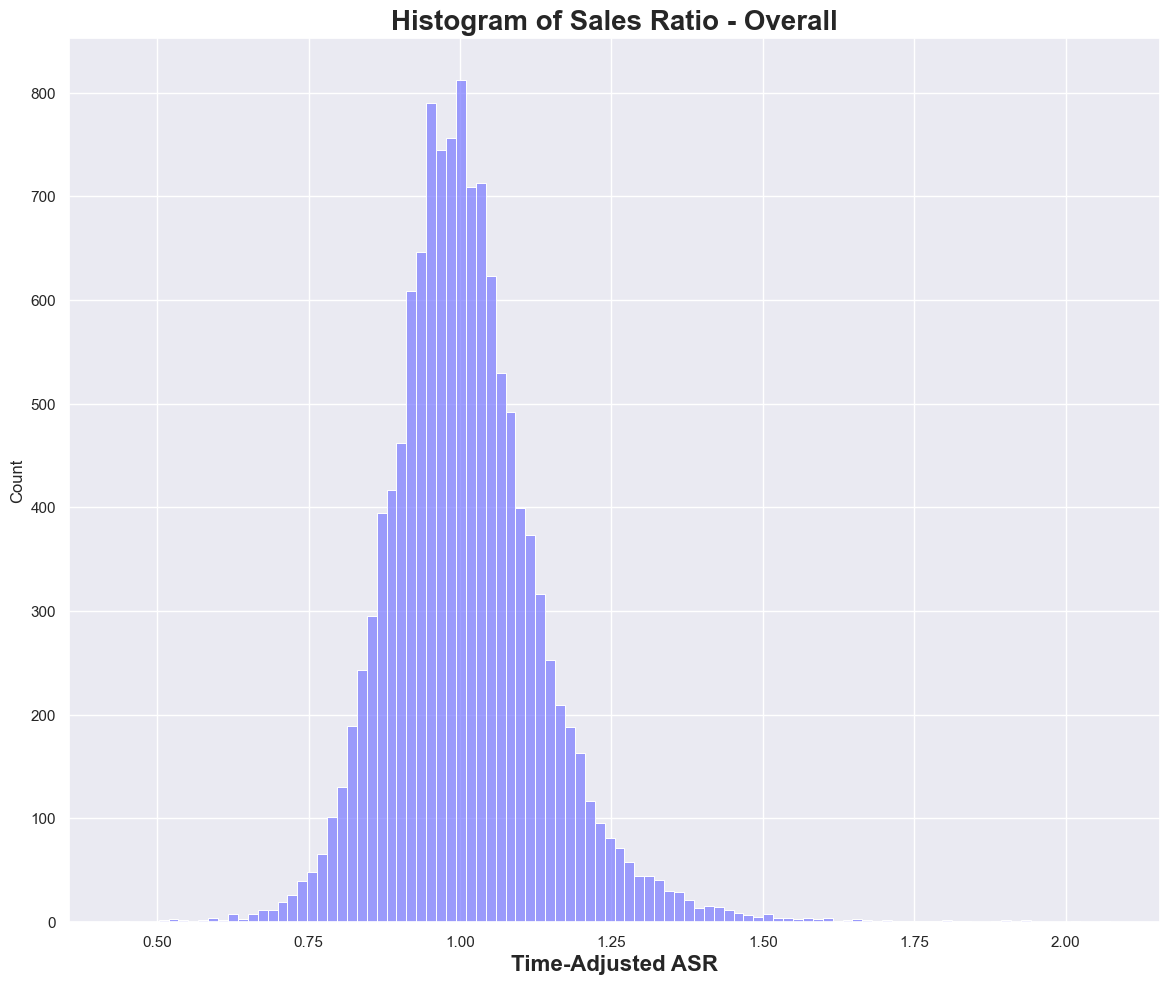

In [5]:
pdf_args = {
    'pdf_starting_comments': [
        'Purpose: annual quality-assurance ratio study for the 2026 assessment cycle.',
        'Sales period: 44 months, time-adjusted to the 1 January 2026 valuation date.',
        'Screening: arm\'s-length sales only, per the Standard on Verification and '
        'Adjustment of Sales (IAAO 2020). No outlier trimming applied.',
        'Standards applied: level 0.90-1.10; COD 5.0-15.0 (residential improved, '
        'Table 11.1); VEI -10% to +10%.',
    ],
    'pdf_ending_comments': [
        'Prepared with the ratio_study package.',
        'Municipal Property Assessment Corporation - ASMA Data Science.',
    ],

    # Columns for the PDF summary tables. These must be real result columns:
    # 'VEM' is not one - the VEM reports as Inequity_conclusion / _severity /
    # _prevalence - and naming it here raises inside the PDF builder.
    'pdf_ratios_table_headers': ['Median', 'CoD', 'VEI', 'PRB', 'PRD'],

    # Chart families
    'pdf_overall_asr_graphs': True,
    'pdf_asr_graphs_x_vars_and_aliases': {
        'overall': {'living_area':   'Living area (sq ft)',
                    'quality_class': 'Quality class',
                    'sale_month':    'Month of sale'},
        'overall_histogram': True,
        'groups': [], 'groups_mosaic': [],
    },
    'pdf_grouping_aliases': {'property_type': 'Property type',
                             'neighbourhood': 'Economic neighbourhood'},

    # The vertical equity panel from section 6, per group as well as overall
    'pdf_vertical_equity_panel': True,
    'pdf_vertical_equity_panel_groups': True,
    'pdf_vertical_equity_panel_min_count': 30,
}

branded_report = rs.ratios_report(sample_df,
                                  assessment_header=ASSESSMENT,
                                  market_value_header=MARKET_VALUE,
                                  group_by=['property_type', 'neighbourhood'],
                                  descriptive=True,
                                  model_name='DemoModel_Branded',
                                  base_date='20260101',
                                  export_directory=results_directory,
                                  export_in_compacted_file='',
                                  pdf_args=pdf_args,
                                  return_dict=False)
branded_report

## 4.3 Exporting the numbers too

`export_ratios` adds the data files, and `export_in_compacted_file` bundles the PDF and the
data into a single archive — the shape you want when a report has to be emailed or attached
to a ticket.

In [6]:
exports = rs.ratios_report(sample_df,
                           assessment_header=ASSESSMENT,
                           market_value_header=MARKET_VALUE,
                           group_by=['property_type', 'neighbourhood'],
                           descriptive=True,
                           model_name='DemoModel_Bundle',
                           export_directory=results_directory,
                           export_ratios='both',              # xlsx + csv
                           export_in_compacted_file='zip',    # ... plus the PDF, zipped
                           return_dict=False)

archive = max(results_directory.glob('ratios_DemoModelBundle_*.zip'),
              key=lambda p: p.stat().st_mtime)
print('archive:', archive.name)

Confidence interval settings  (<-- marks a value you set or is a default setting)
  Mode                  : distribution
  Level                 : 90%
  Indicators            : Median, Mean, Weighted_Mean, CoD, PRB, PRD
  Overall intervals     : on
  Per-group intervals   : off
  Minimum sales per row : 20
  Estimators            : Appendix D closed forms, plus PRB (regression) and PRD (delta method); bootstrap options ignored
VEI quantile method: R7


archive: ratios_DemoModelBundle_29sep2026_14h49.zip


In [7]:
import zipfile

with zipfile.ZipFile(archive) as z:
    for info in z.infolist():
        print(f'{info.file_size:>10,}  {info.filename}')

    30,200  ratio_study_DemoModelBundle_29sep2026_14h49.csv
    15,345  ratio_study_DemoModelBundle_29sep2026_14h49.xlsx
   408,776  ratio_study_DemoModelBundle_29sep2026_14h49.pdf


## 4.4 PNG output for slides

Any chart function writes a PNG when given `graph_filepath`, and returns the path.

## 4.4 PNG output for slides

Any chart function writes a PNG when given `graph_filepath`, and returns the path.

In [8]:
panel_png = rs.vertical_equity_panel(
    sample_df,
    assessment_header=ASSESSMENT,
    market_value_header=MARKET_VALUE,
    title='Vertical Equity Panel',
    subtitle='DemoModel - all sales',
    graph_filepath=str(results_directory / 've_panel.png'))

print('saved:', panel_png)

saved: <path>

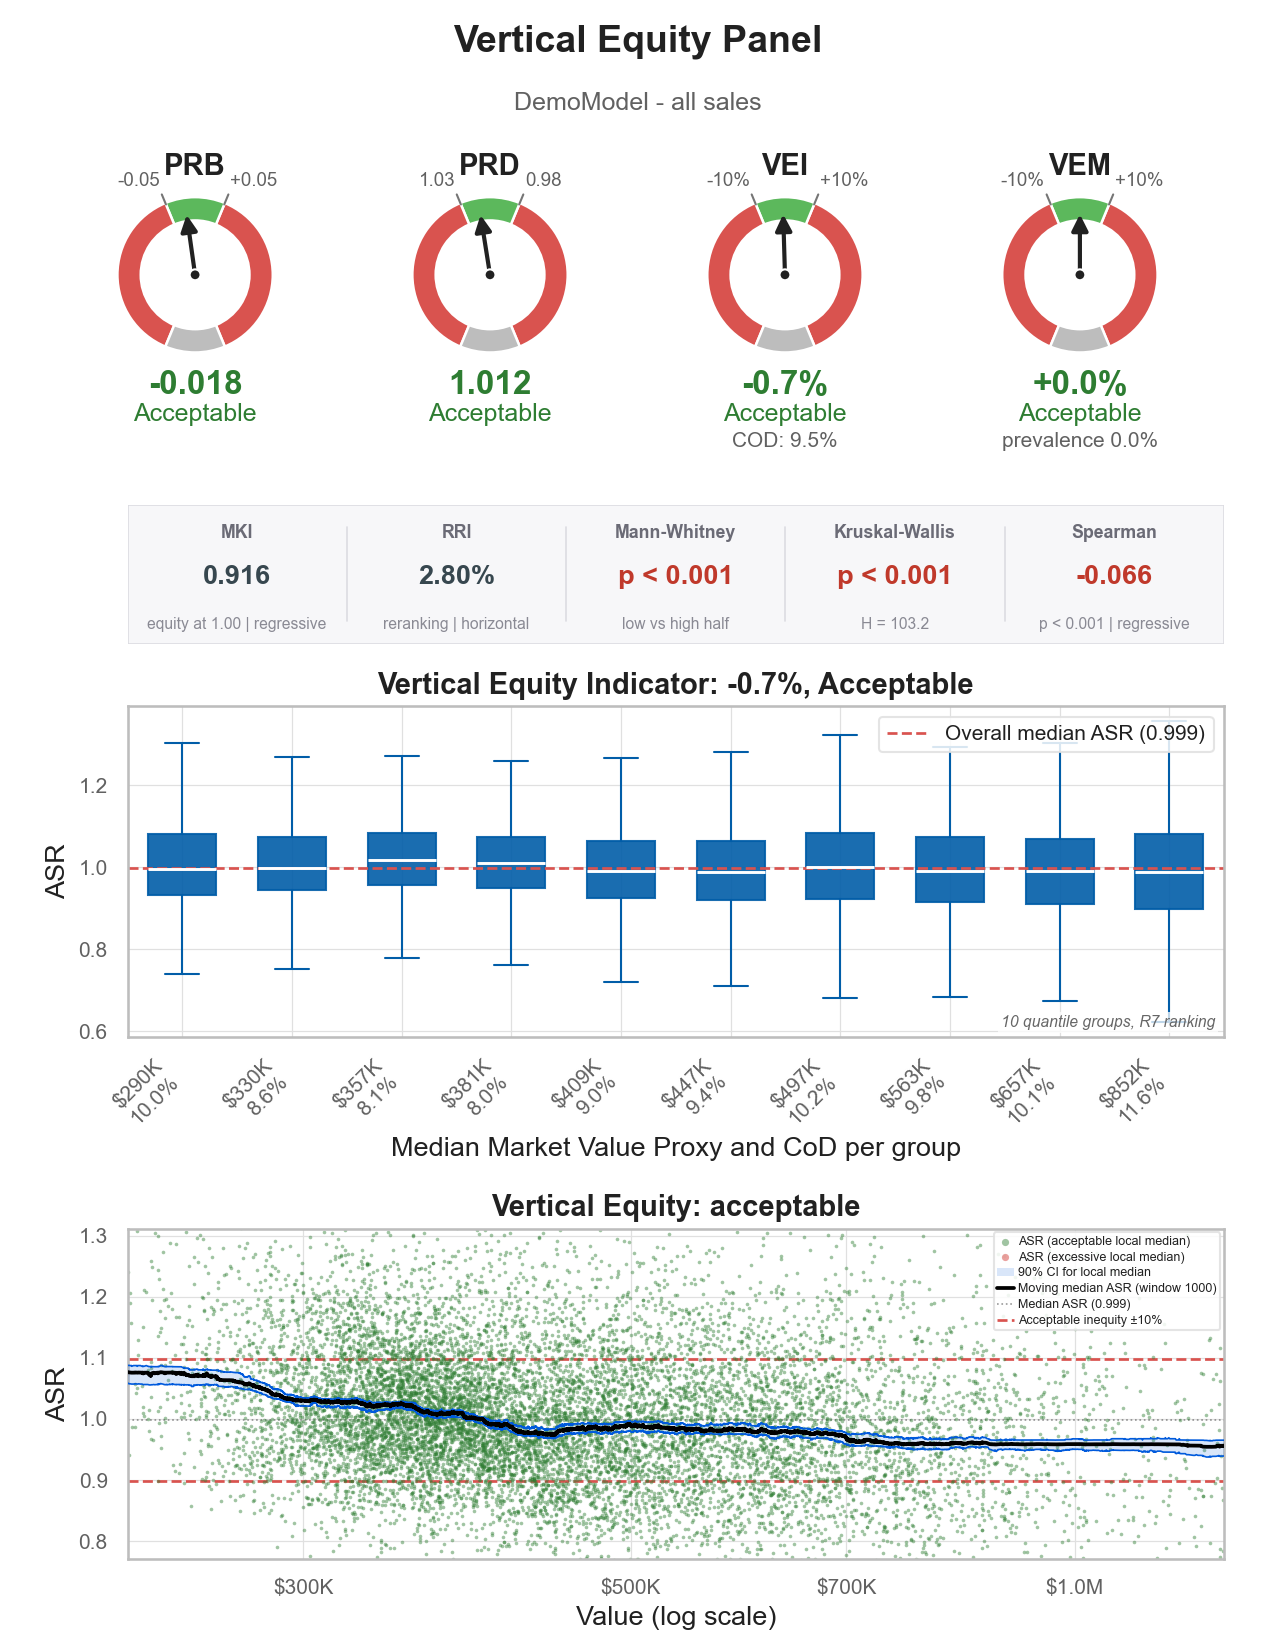

In [9]:
from IPython.display import Image, display
display(Image(filename=panel_png, width=620))

---
**Next:** [04 Advanced diagnostics](04_advanced_diagnostics.ipynb) shows the ML page of the report in detail.